## Objective
The goal of this project is to predict whether a telecommunications customer will leave the service (`Churn Value = 1`) or remain with the company (`Churn Value = 0`).

The workflow covers data inspection, cleaning, preprocessing, model comparison, validation-based threshold selection, and final evaluation on an untouched test set.

## Evaluation focus
Because missing a customer who is likely to churn can be costly, **Recall for the Churn class** is an important metric. Precision must also be considered because false alarms may lead to unnecessary retention calls or discounts.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load the dataset

The project uses the Telco Customer Churn dataset. The initial inspection checks the dataset dimensions, sample records, column types, and target-related fields before any preprocessing is performed.

In [3]:
df = pd.read_csv('Telco_customer_churn.csv')

In [4]:
df.shape

(7043, 33)

In [5]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


## Initial data inspection

The following cells inspect the available values and cardinality of the columns. This helps distinguish identifiers, 

In [6]:
df['Churn Reason'].unique()

array(['Competitor made better offer', 'Moved',
       'Competitor had better devices',
       'Competitor offered higher download speeds',
       'Competitor offered more data', 'Price too high',
       'Product dissatisfaction', 'Service dissatisfaction',
       'Lack of self-service on Website', 'Network reliability',
       'Limited range of services',
       'Lack of affordable download/upload speed',
       'Long distance charges', 'Extra data charges', "Don't know",
       'Poor expertise of online support',
       'Poor expertise of phone support', 'Attitude of service provider',
       'Attitude of support person', 'Deceased', nan], dtype=object)

In [7]:
df['Churn Value'].unique()

array([1, 0])

In [8]:
df['Churn Label'].unique()

array(['Yes', 'No'], dtype=object)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [10]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

CustomerID: 7043 unique values
Count: 1 unique values
Country: 1 unique values
State: 1 unique values
City: 1129 unique values
Zip Code: 1652 unique values
Lat Long: 1652 unique values
Latitude: 1652 unique values
Longitude: 1651 unique values
Gender: 2 unique values
Senior Citizen: 2 unique values
Partner: 2 unique values
Dependents: 2 unique values
Tenure Months: 73 unique values
Phone Service: 2 unique values
Multiple Lines: 3 unique values
Internet Service: 3 unique values
Online Security: 3 unique values
Online Backup: 3 unique values
Device Protection: 3 unique values
Tech Support: 3 unique values
Streaming TV: 3 unique values
Streaming Movies: 3 unique values
Contract: 3 unique values
Paperless Billing: 2 unique values
Payment Method: 4 unique values
Monthly Charges: 1585 unique values
Total Charges: 6531 unique values
Churn Label: 2 unique values
Churn Value: 2 unique values
Churn Score: 85 unique values
CLTV: 3438 unique values
Churn Reason: 20 unique values


## Remove unsuitable columns

The following columns are excluded from the baseline feature set:

- `CustomerID`: unique customer identifier, not a generalizable customer behavior feature.
- `Count`, `Country`, and `State`: constant columns in this dataset.
- `City`, `Zip Code`, `Lat Long`, `Latitude`, and `Longitude`: high-cardinality or redundant geographic fields, excluded from this baseline.
- `Churn Label`: duplicate text representation of the target.
- `Churn Score`: precomputed churn score that could introduce target leakage.
- `Churn Reason`: only meaningful/available for customers who churned and would leak information about the outcome.

`Churn Value` is retained as the target.


In [11]:
columns_to_drop = [
    'CustomerID',
    'Count',
    'Country',
    'State',
    'City',
    'Zip Code',
    'Lat Long',
    'Latitude',
    'Longitude',
    'Churn Label',
    'Churn Score',
    'Churn Reason'
]

df = df.drop(columns=columns_to_drop)

In [12]:
df

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,...,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,CLTV
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,3239
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,2701
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,1,5372
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1,5003
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,1,5340
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Female,No,No,No,72,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),21.15,1419.4,0,5306
7039,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,...,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,0,2140
7040,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,0,5560
7041,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0,2793


## Convert `Total Charges` to numeric

`Total Charges` is initially stored as an object column. It is converted to a numeric type; values that cannot be parsed are temporarily represented as missing values so they can be inspected explicitly.


In [13]:
df['Total Charges'] = pd.to_numeric(
    df['Total Charges'],
    errors='coerce'
)

## Define features and target

- **Target (`y`):** `Churn Value`
- **Features (`X`):** all remaining columns after removing the excluded fields and target column.

The target distribution is inspected because class imbalance can affect model evaluation and the interpretation of Accuracy.


In [14]:
X = df.drop(columns=['Churn Value'])
y = df['Churn Value']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget distribution (%):")
print((y.value_counts(normalize=True) * 100).round(2))

Features shape: (7043, 20)
Target shape: (7043,)

Target distribution:
Churn Value
0    5174
1    1869
Name: count, dtype: int64

Target distribution (%):
Churn Value
0    73.46
1    26.54
Name: proportion, dtype: float64


## Inspect missing values

The missing-value check identifies columns that require attention before model training. In this dataset, the missing values occur in `Total Charges`.


In [15]:
miss_val = df.isnull().sum()
miss_val= miss_val[miss_val > 0]
miss_val

Total Charges    11
dtype: int64

In [16]:
missing_rows = df[df['Total Charges'].isnull()]
display(missing_rows[['Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Value']])

,Tenure Months,Monthly Charges,Total Charges,Churn Value
2234,0,52.55,NaN,0
2438,0,20.25,NaN,0
2568,0,80.85,NaN,0
2667,0,25.75,NaN,0
2856,0,56.05,NaN,0
4331,0,19.85,NaN,0
4687,0,25.35,NaN,0
5104,0,20.00,NaN,0
5719,0,19.70,NaN,0
6772,0,73.35,NaN,0


## Handle missing values

The 11 missing `Total Charges` values are filled with zero based on the inspection above. The feature matrix and target are then re-created from the cleaned dataframe.


In [17]:
df['Total Charges'] = df['Total Charges'].fillna(0)

X = df.drop(columns=['Churn Value'])
y = df['Churn Value']

## Separate numerical and categorical features

The predictors are divided by data type:

- **Numerical features (4):** `Tenure Months`, `Monthly Charges`, `Total Charges`, and `CLTV`.
- **Categorical features (16):** `Gender`, `Senior Citizen`, `Partner`, `Dependents`, `Phone Service`, `Multiple Lines`, `Internet Service`, `Online Security`, `Online Backup`, `Device Protection`, `Tech Support`, `Streaming TV`, `Streaming Movies`, `Contract`, `Paperless Billing`, and `Payment Method`.

`Senior Citizen` is treated as categorical because it represents membership in a category rather than a continuous measurement.


In [18]:
numerical_features = X.select_dtypes(include=['int64' , 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

print("\nNumerical count:", len(numerical_features))
print("Categorical count:", len(categorical_features))

Numerical Features: ['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']

Categorical Features: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']

Numerical count: 4
Categorical count: 16


## Train-test split

The dataset is split into training and test subsets using an 80/20 split. Stratification preserves the target-class proportions in both subsets.

The observed class distribution is approximately:

- No Churn: 73.46%
- Churn: 26.54%

The test set is held out for the final evaluation and is not used to select the classification threshold.


In [19]:
from sklearn.model_selection import train_test_split

X_train,X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=1234 , stratify=y)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

X_train shape: (5634, 20)
X_test shape: (1409, 20)

Training target distribution:
Churn Value
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing target distribution:
Churn Value
0    0.734564
1    0.265436
Name: proportion, dtype: float64


## Preprocessing

A `ColumnTransformer` applies separate transformations to the two feature groups:

- `StandardScaler` standardizes numerical features.
- `OneHotEncoder(handle_unknown='ignore')` converts categorical features into indicator columns and safely handles categories that may appear only in validation or test data.

The transformer is placed inside each modeling pipeline. Therefore, preprocessing is fitted on the training data only, reducing the risk of data leakage.


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder , StandardScaler

preprocessor = ColumnTransformer(
    transformers = [
        ('num' , StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore') , categorical_features)
    ]
)

## Baseline classification models

Three classifiers are compared:

1. **Logistic Regression** — a linear classification baseline.
2. **K-Nearest Neighbors (KNN)** — predicts based on nearby training observations.
3. **Decision Tree** — learns rule-based splits in the feature space.

All models use the same preprocessing pipeline and training split to make the comparison consistent.


In [21]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=1234)
}

In [22]:
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(
        [
         ('preprocessor', preprocessor),
        ('classifier', model)   
        ]
    )
    pipeline.fit(X_train,y_train)
    trained_models[name] = pipeline

    print(f'{name} trained successfuly')

Logistic Regression trained successfuly
KNN trained successfuly
Decision Tree trained successfuly


## Baseline model evaluation

The models are evaluated on the held-out test set using Accuracy, Precision, Recall, and F1-score.

For this task, the positive class is `Churn Value = 1`:

- **Precision:** among customers predicted to churn, the proportion who actually churn.
- **Recall:** among customers who actually churn, the proportion identified by the model.
- **F1-score:** the harmonic mean of Precision and Recall.

The baseline results were:

| Model | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.7892 | 0.6170 | 0.5428 | 0.5775 |
| KNN | 0.7551 | 0.5387 | 0.5401 | 0.5394 |
| Decision Tree | 0.7431 | 0.5162 | 0.5107 | 0.5134 |

Logistic Regression performed best among the three baseline models. However, its Churn recall was only about 54%, meaning that a substantial share of customers who churned were not identified.


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.7892,0.6170,0.5428,0.5775
1,KNN,0.7551,0.5387,0.5401,0.5394
2,Decision Tree,0.7431,0.5162,0.5107,0.5134


## Baseline confusion matrices

The confusion matrices show the types and counts of prediction errors:

- **True Negative (TN):** correctly predicted No Churn.
- **False Positive (FP):** predicted Churn, but the customer did not churn.
- **False Negative (FN):** predicted No Churn, but the customer actually churned.
- **True Positive (TP):** correctly predicted Churn.

False Negatives are particularly relevant when the business wants to identify customers at risk before they leave.


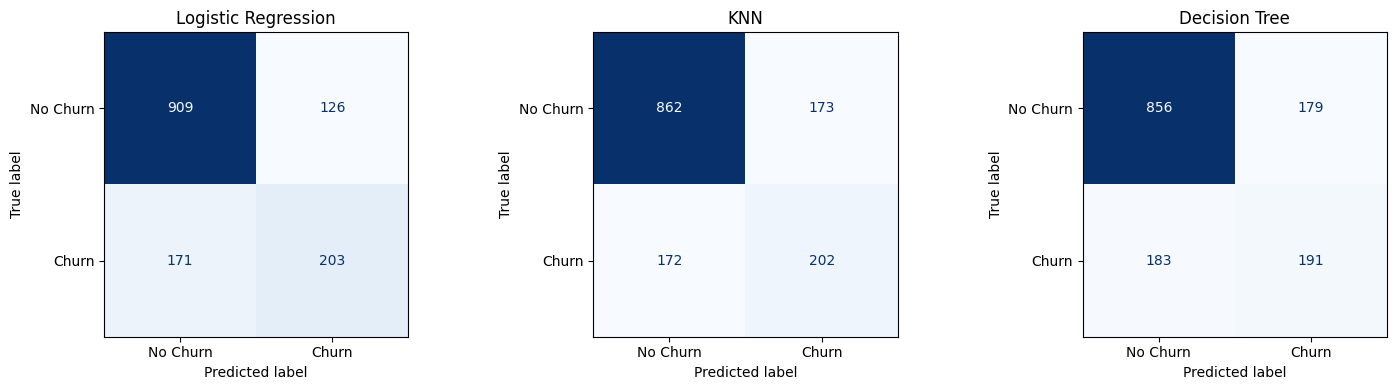

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, trained_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Churn', 'Churn']
    )

    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

## Validation split and class-weight experiment

The original training set is split again into a smaller training subset and a validation subset. The validation subset is used for model comparison and threshold selection, while the original test set remains untouched.

A class-weighted Logistic Regression model is also fitted. With `class_weight='balanced'`, the classifier gives greater weight to the minority Churn class during training. This can improve Churn recall, but it may also increase false positives and reduce precision.


In [25]:
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

lr_balanced = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

lr_balanced.fit(X_train_new, y_train_new)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [26]:
results = []

models_to_compare = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Logistic Regression (Balanced)': LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=1234)
}

validation_models = {}

for name, model in models_to_compare.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train_new, y_train_new)

    y_pred = pipeline.predict(X_val)

    validation_models[name] = pipeline

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred),
        'Recall': recall_score(y_val, y_pred),
        'F1-score': f1_score(y_val, y_pred)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.8252,0.6903,0.6187,0.6526
1,Logistic Regression (Balanced),0.7657,0.5390,0.8094,0.6471
2,KNN,0.7711,0.5768,0.5151,0.5442
3,Decision Tree,0.7356,0.5017,0.5017,0.5017


## Compare Logistic Regression with and without class weighting

Validation confusion matrices illustrate the trade-off introduced by class weighting.

The observed validation results were:

| Model | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.8252 | 0.6903 | 0.6187 | 0.6526 |
| Logistic Regression (Balanced) | 0.7657 | 0.5390 | 0.8094 | 0.6471 |
| KNN | 0.7711 | 0.5768 | 0.5151 | 0.5442 |
| Decision Tree | 0.7356 | 0.5017 | 0.5017 | 0.5017 |

Class weighting increased Recall from 61.87% to 80.94%, while reducing Precision from 69.03% to 53.90%. This is a trade-off rather than an unconditional improvement.


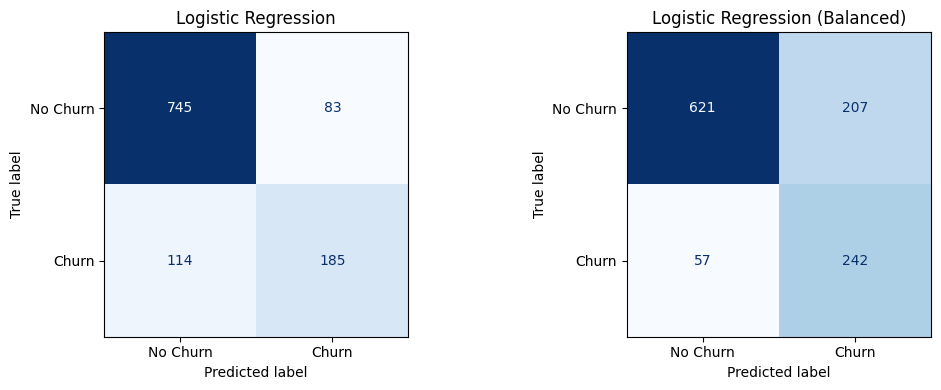

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, name in zip(
    axes,
    ['Logistic Regression', 'Logistic Regression (Balanced)']
):
    model = validation_models[name]
    y_pred = model.predict(X_val)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_pred,
        display_labels=['No Churn', 'Churn'],
        cmap='Blues',
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

## Classification threshold selection

Logistic Regression produces a probability score for the Churn class. The default decision threshold is 0.50, but it can be adjusted to change the balance between Precision and Recall.

The threshold is selected using the validation set, not the test set. The validation results were:

| Threshold | Precision | Recall | F1-score |
|---:|---:|---:|---:|
| 0.30 | 0.5735 | 0.7826 | 0.6620 |
| 0.35 | 0.6087 | 0.7492 | **0.6717** |
| 0.40 | 0.6176 | 0.7023 | 0.6573 |
| 0.45 | 0.6408 | 0.6622 | 0.6513 |
| 0.50 | 0.6903 | 0.6187 | 0.6526 |
| 0.55 | 0.7130 | 0.5485 | 0.6200 |
| 0.60 | 0.7696 | 0.4916 | 0.6000 |

A threshold of **0.35** is selected because it achieved the highest validation F1-score among the tested thresholds, while retaining higher Recall than the default threshold. This choice reflects a preference for identifying more at-risk customers, accepting that more false-positive alerts may occur.

The threshold is a modeling decision, not a universally optimal business value. A real deployment should consider the relative costs of missed churners and unnecessary retention actions.


In [28]:
lr_model = validation_models['Logistic Regression']

y_proba = lr_model.predict_proba(X_val)[:, 1]

thresholds = [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]

threshold_results = []

for threshold in thresholds:
    y_pred = (y_proba >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred),
        'Recall': recall_score(y_val, y_pred),
        'F1-score': f1_score(y_val, y_pred)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-score
0,0.30,0.5735,0.7826,0.6620
1,0.35,0.6087,0.7492,0.6717
2,0.40,0.6176,0.7023,0.6573
3,0.45,0.6408,0.6622,0.6513
4,0.50,0.6903,0.6187,0.6526
5,0.55,0.7130,0.5485,0.6200
6,0.60,0.7696,0.4916,0.6000


## Final model training and test prediction

After selecting the model type and threshold using the training/validation data, Logistic Regression is refitted on the full training set. The selected threshold (0.35) is then applied to predicted probabilities on the untouched test set.

The test set is used only for this final evaluation, providing a more realistic estimate of performance on unseen customers.


In [29]:
final_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

final_model.fit(X_train, y_train)

# Predict churn probabilities
y_proba_test = final_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
selected_threshold = 0.35
y_pred_final = (y_proba_test >= selected_threshold).astype(int)

## Final test-set metrics

The final model achieved:

| Metric | Test result |
|---|---:|
| Accuracy | 0.7630 |
| Precision | 0.5420 |
| Recall | 0.6898 |
| F1-score | 0.6071 |

The test Recall is lower than the validation Recall at threshold 0.35 (74.92%), but it still identifies approximately 69% of customers who actually churned. The difference between validation and test performance indicates that results on unseen data are somewhat weaker, which is important to report rather than relying only on validation scores.


In [30]:
print("Final Test Results")

print("Accuracy:", round(accuracy_score(y_test, y_pred_final), 4))
print("Precision:", round(precision_score(y_test, y_pred_final), 4))
print("Recall:", round(recall_score(y_test, y_pred_final), 4))
print("F1-score:", round(f1_score(y_test, y_pred_final), 4))

Final Test Results
Accuracy: 0.763
Precision: 0.542
Recall: 0.6898
F1-score: 0.6071


## Final confusion matrix and interpretation

The final test confusion matrix is:

| | Predicted No Churn | Predicted Churn |
|---|---:|---:|
| **Actual No Churn** | 817 | 218 |
| **Actual Churn** | 116 | 258 |

Interpretation:

- 258 of the 374 actual churners were correctly identified.
- 116 actual churners were missed (False Negatives).
- 218 customers were incorrectly flagged as likely to churn (False Positives).
- 817 non-churning customers were correctly classified.

The model therefore identifies 68.98% of actual churners, while approximately 45.8% of its Churn predictions are false alarms (equivalently, Precision is 54.2%).

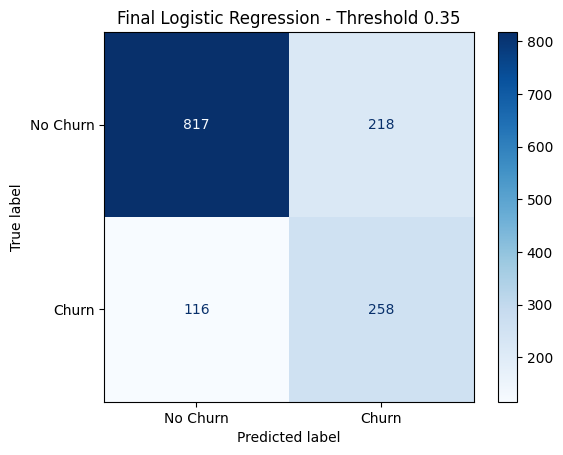

In [31]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues'
)

plt.title('Final Logistic Regression - Threshold 0.35')
plt.show()

## Conclusion

Logistic Regression was the strongest baseline model among the three classifiers tested. Class weighting substantially increased Churn recall on validation data, but also increased false positives and reduced precision. Adjusting the classification threshold provided another way to manage this trade-off.

The final Logistic Regression model, using a threshold of 0.35, achieved **76.30% Accuracy, 54.20% Precision, 68.98% Recall, and 60.71% F1-score** on the test set.

The model is useful as a baseline churn-identification exercise, but it should not be described as deployment-ready. The appropriate threshold depends on business costs: missing a customer who churns may be more expensive than contacting a customer who would have stayed, but this must be confirmed with actual retention and customer-value data. Further work could include cross-validation, hyperparameter tuning, calibration, and cost-based threshold selection.
